In [6]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [7]:
OUT = "/content/drive/MyDrive/crop price pr"

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.preprocessing import StandardScaler, PolynomialFeatures, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import r2_score, mean_squared_error
import requests

In [9]:
import pandas as pd

df = pd.read_csv('/content/drive/MyDrive/crop price pr/hp_onion_full_kaggle.csv',parse_dates=["date"])
festivals=pd.read_excel('/content/drive/MyDrive/crop price pr/festival_calendar.xlsx',parse_dates=["date"])

In [10]:
print("Loaded: ",df.shape)

Loaded:  (9617, 10)


In [11]:
print(df["market_name"].nunique(),"markets")

29 markets


In [12]:
print(df["date"].min() ,"to" ,df["date"].max())

2023-01-07 00:00:00 to 2025-12-05 00:00:00


In [14]:
fest_dates=festivals["date"].sort_values().to_numpy()

In [15]:
def nearest_gap(d):
  diffs=(fest_dates - np.datetime64(d))/np.timedelta64(1,"D")
  idx=np.argmin(np.abs(diffs))
  return diffs[idx]
df["days_to_festival"]=df["date"].apply(nearest_gap)
df["is_festival_week"]=df["days_to_festival"].abs()<=7
df["month"]=df["date"].dt.month
df["day_of_year"]=df["date"].dt.dayofyear
df["year"]=df["date"].dt.year
def season(m):
  if m in [12,1,2]:
    return "winter"
  if m in [3,4,5]:
    return "summer"
  if m in [6,7,8,9]:
    return "monsoon"
  return "post monsoon"
df["season"]=df["month"].apply(season)

In [16]:
SHIMLA_LAT = 31.1048
SHIMLA_LON = 77.1734

def fetch_weather(start_date, end_date):
    url = "https://archive-api.open-meteo.com/v1/archive"
    params = {
        "latitude": SHIMLA_LAT,
        "longitude": SHIMLA_LON,
        "start_date": start_date,
        "end_date": end_date,
        "daily": "precipitation_sum,temperature_2m_mean",
        "timezone": "Asia/Kolkata",
    }
    response = requests.get(url, params=params)
    response.raise_for_status()
    data = response.json()
    return pd.DataFrame({
        "date": pd.to_datetime(data["daily"]["time"]),
        "rainfall_mm": data["daily"]["precipitation_sum"],
        "temp_avg_c": data["daily"]["temperature_2m_mean"],
    })

weather = fetch_weather("2023-01-01", "2025-12-31")
weather.to_csv(f"{OUT}/weather_shimla.csv", index=False)
print("Weather fetched:", weather.shape)

df = df.merge(weather, on="date", how="left")
print("After merging weather:", df.shape)
print(df[["date", "modal_price", "rainfall_mm", "temp_avg_c"]].head())


Weather fetched: (1096, 3)
After merging weather: (9617, 18)
        date  modal_price  rainfall_mm  temp_avg_c
0 2023-01-07       1160.0          0.6         5.8
1 2023-01-07       1750.0          0.6         5.8
2 2023-01-07       1175.0          0.6         5.8
3 2023-01-07       2250.0          0.6         5.8
4 2023-01-07       2000.0          0.6         5.8


In [17]:
top_markets=df["market_name"].value_counts().head(5).index.tolist()

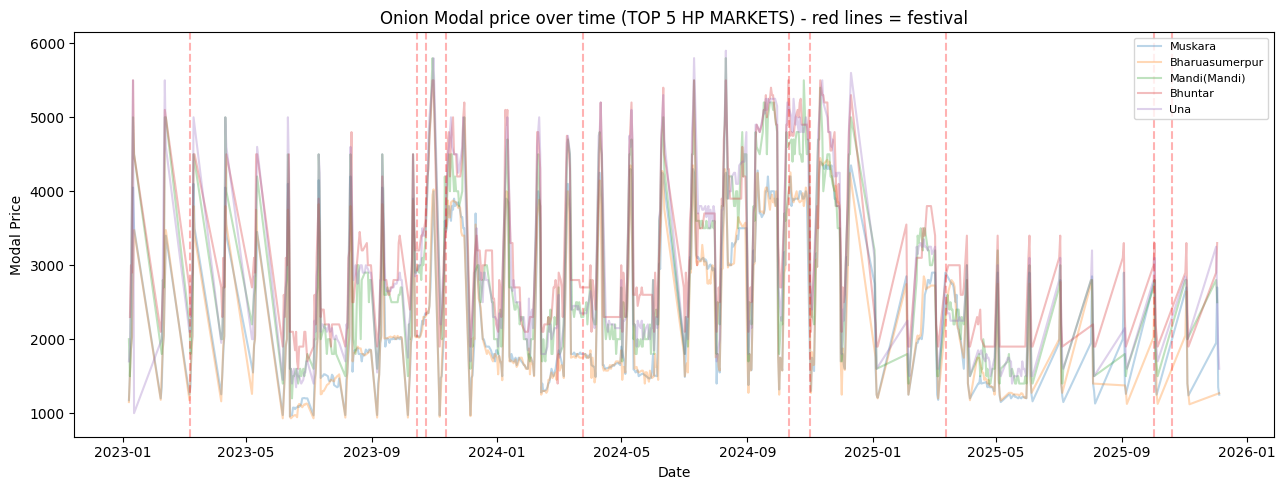

In [18]:
plt.figure(figsize=(13,5))
for m in top_markets:
  sub=df[df["market_name"]==m].sort_values("date")
  plt.plot(sub["date"],sub["modal_price"],label=m,alpha=0.3)
for _,row in festivals.iterrows():
  plt.axvline(row["date"],color="red",linestyle="--",alpha=0.3)
plt.title("Onion Modal price over time (TOP 5 HP MARKETS) - red lines = festival")
plt.xlabel("Date")
plt.ylabel("Modal Price")
plt.legend(fontsize=8)
plt.tight_layout()
plt.savefig(f"{OUT}/price_trend.png",dpi=120)
plt.show()
plt.close()

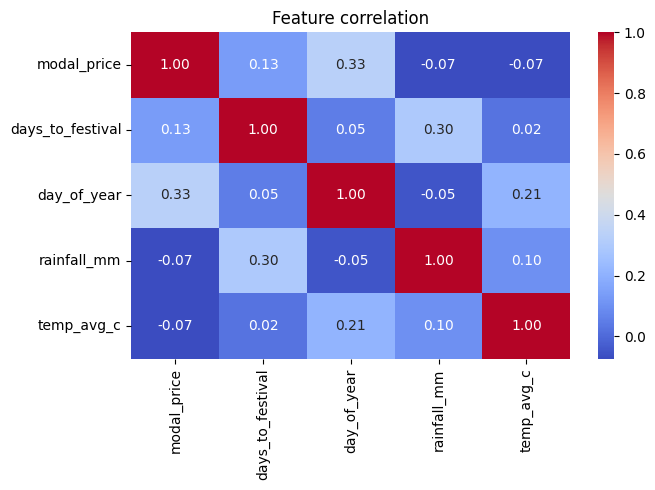

In [19]:
plt.figure(figsize=(7,5))
num_cols=["modal_price","days_to_festival","day_of_year","rainfall_mm","temp_avg_c"]
sns.heatmap(df[num_cols].corr(),annot=True,cmap="coolwarm",fmt=".2f")
plt.title("Feature correlation")
plt.tight_layout()
plt.savefig(f"{OUT}/correlation_heatmap.png",dpi=120)
plt.show()

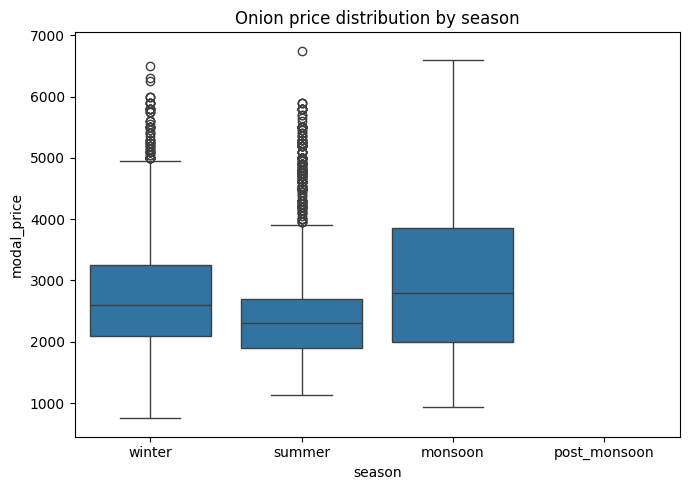

In [20]:
plt.figure(figsize=(7,5))
sns.boxplot(data=df,x="season",y="modal_price",order=["winter","summer","monsoon","post_monsoon"])
plt.title("Onion price distribution by season")
plt.tight_layout()
plt.savefig(f"{OUT}/price_by_season.png",dpi=120)
plt.show()

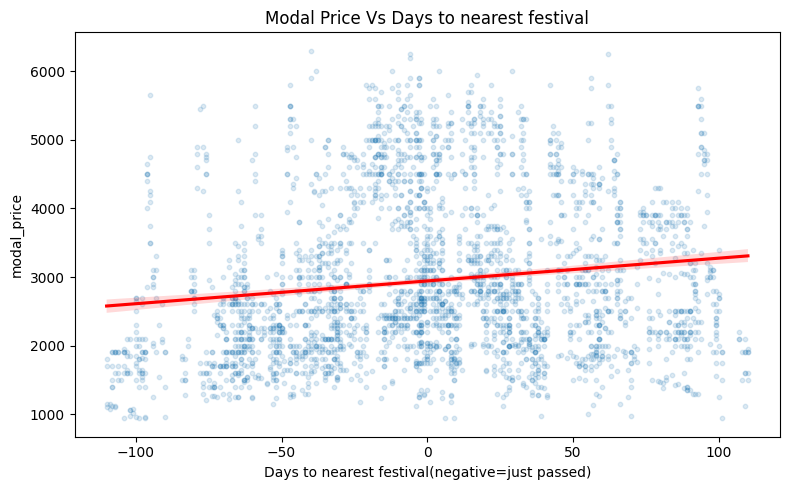

In [21]:
plt.figure(figsize=(8,5))
sns.regplot(data=df.sample(min(3000 , len(df)), random_state=1),x="days_to_festival",y="modal_price", scatter_kws={"alpha":0.15, "s":10},line_kws={"color":"red"})
plt.title("Modal Price Vs Days to nearest festival")
plt.xlabel("Days to nearest festival(negative=just passed)")
plt.tight_layout()
plt.savefig(f"{OUT}/price_vs_festival_gap.png",dpi=120)
plt.show()

In [22]:
features_num=["days_to_festival","day_of_year","rainfall_mm","temp_avg_c"]
features_cat=["market_name","season","year"]
target="modal_price"

data=df.dropna(subset=features_num + features_cat + [target]).sort_values("date")

In [23]:
train,test=train_test_split(data,test_size=0.2,random_state=42)
x_train,y_train=train[features_num + features_cat],train[target]
x_test,y_test=test[features_num+features_cat],test[target]

In [24]:
preprocess=ColumnTransformer([("num",StandardScaler(),features_num ), ("cat",OneHotEncoder(handle_unknown="ignore"),features_cat),])

In [25]:
models = {
    "Linear Regression": Pipeline([
        ("prep", preprocess),
        ("model", LinearRegression()),
    ]),
    "Polynomial (deg=2) + Ridge": Pipeline([
        ("prep", preprocess),
        ("poly", PolynomialFeatures(degree=2, include_bias=False)),
        ("model", Ridge(alpha=1.0)),
    ]),
    "Ridge (deg=1)": Pipeline([
        ("prep", preprocess),
        ("model", Ridge(alpha=1.0)),
    ]),
}

In [26]:
print("Model results")
results={}
for name,pipe in models.items():
  pipe.fit(x_train,y_train)
  preds=pipe.predict(x_test)
  r2=r2_score(y_test,preds)
  mse=mean_squared_error(y_test,preds)
  cv_scores=cross_val_score(pipe,x_train,y_train,cv=5,scoring="r2")
  results[name]={"r2":round(r2,3),"MSE":round(mse,1),"CV_R2_mean":round(cv_scores.mean(),3)}
  print(f"{name}:{results[name]}")
  pd.DataFrame(results).T.to_csv(f"{OUT}/model_results.csv")
  print("\nSaved model_results.csv")


Model results
Linear Regression:{'r2': 0.4, 'MSE': 744653.1, 'CV_R2_mean': np.float64(0.421)}

Saved model_results.csv
Polynomial (deg=2) + Ridge:{'r2': 0.528, 'MSE': 585586.8, 'CV_R2_mean': np.float64(0.571)}

Saved model_results.csv
Ridge (deg=1):{'r2': 0.4, 'MSE': 744549.5, 'CV_R2_mean': np.float64(0.421)}

Saved model_results.csv
